# SMART VINEYARD
## BÀI 2: PHÂN TÍCH PHÂN BỐ BỆNH VÀ MỐI LIÊN HỆ MÔI TRƯỜNG

Phân tích metadata (vườn, GPS, thời tiết, ánh sáng, thời điểm chụp, loại bệnh) để:

| Mục tiêu | Kỹ thuật |
|---|---|
| Phân bố bệnh theo từng vườn, xác định vườn cần ưu tiên khảo sát | Tỷ lệ bệnh + khoảng tin cậy Wilson, kiểm định nhị thức và chi-square, hiệu chỉnh FDR, kiểm tra độ ổn định của xếp hạng |
| Khám phá nhóm vườn có đặc điểm bệnh tương đồng | K-Means / phân cấp Ward + kiểm định hoán vị, bản đồ GPS, Mantel test |
| Tìm mối liên hệ giữa môi trường, vị trí và tình trạng bệnh | Luật kết hợp (support, confidence, lift) + kiểm định Fisher + FDR |
| Kiểm tra metadata có giải thích được bệnh không | Cross-validation so với mô hình đoán lớp phổ biến nhất + kiểm định hoán vị |

> **Lưu ý:** đây là phân tích **mối liên hệ trong dữ liệu**, không chứng minh môi trường gây ra bệnh.

### Dữ liệu và cách xử lý phụ thuộc giữa các bản ghi
Dữ liệu lấy từ bước `03_Image_Preprocessing` (thư mục `outputs/processed/step03_clean`). Ở bước trước đã phát hiện:
- Khoảng 31% bản ghi là bản sao của cùng một ảnh, và các bản sao này **mang metadata khác nhau** (một ảnh gắn với nhiều vườn, nhiều thời điểm). Metadata vì vậy có dấu hiệu không gắn chặt với nội dung ảnh.
- Các bản ghi cùng một ảnh **không độc lập**, nên kiểm định thông thường (chi-square, nhị thức) có thể cho p-value nhỏ hơn thực tế.

Vì vậy notebook dùng hai bản dữ liệu song song:

| Bản | Số bản ghi | Vai trò |
|---|---|---|
| **Dedup** | 2.047 (mỗi ảnh một dòng) | **Kết quả chính** cho các kiểm định, vì các bản ghi độc lập |
| **Full** | 2.904 (nhất quán, chưa khử trùng) | Đối chứng. Kiểm định dùng **hoán vị theo nhóm ảnh** (nhóm MD5) để tính đến sự phụ thuộc |

Nếu kết luận giống nhau ở cả hai bản thì kết luận đó đáng tin cậy.

**1. IMPORT THƯ VIỆN**

In [1]:
import re, json, itertools, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold,
                                     cross_validate, permutation_test_score)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Đã import thư viện xong.")

Đã import thư viện xong.


**2. CẤU HÌNH**

In [2]:
# ======================= CẤU HÌNH =======================
PROJECT_DIR = Path(r"D:\DataMining26\Smart-Vineyard")          # <- đổi nếu project nằm nơi khác
STEP03_DIR = PROJECT_DIR / "outputs" / "processed" / "step03_clean"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "bai2"

SEED = 42
ALPHA = 0.05
N_PERMUTATIONS = 1000          # hoán vị cho Mantel test và chi-square theo nhóm
N_PERM_CLUSTER = 200           # hoán vị cho kiểm định cụm
N_PERM_MODEL = 30              # hoán vị cho kiểm định khả năng dự đoán
N_SPLIT_HALF = 500             # số lần chia đôi để kiểm tra độ ổn định xếp hạng vườn
MIN_SUPPORT = 0.01             # support tối thiểu của luật kết hợp
# =========================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

def savefig(name):
    name = re.sub(r"\W+", "_", name).strip("_")
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Thư mục dữ liệu bước 03:", STEP03_DIR, "| tồn tại:", STEP03_DIR.exists())

Thư mục dữ liệu bước 03: D:\DataMining26\Smart-Vineyard\outputs\processed\step03_clean | tồn tại: True


**3. ĐỌC DỮ LIỆU**

Đọc `task2_env_dedup.csv` (bản chính) và `task2_env_full.csv` (đối chứng). File `removed_label_conflicts.csv` chứa các bản ghi đã bị loại vì ảnh nằm ở nhiều lớp bệnh (nhãn mơ hồ). Ghép lại với bản Full sẽ được bản **All** (3.476 bản ghi), dùng cho phân tích độ nhạy.

In [3]:
RENAME = {
    "Location.Vineyard": "Vineyard",
    "Location.GPS.Latitude": "Lat",
    "Location.GPS.Longitude": "Lon",
    "Environmental_Conditions.Time_of_Capture": "Time",
    "Environmental_Conditions.Lighting": "Lighting",
    "Environmental_Conditions.Weather": "Weather",
    "Disease_Type": "Disease",
    "Plant_Health_Status": "Health",
}
REQUIRED = ["MD5", "Disease", "Health", "Vineyard", "Lat", "Lon", "Time", "Lighting", "Weather"]

def load(path):
    d = pd.read_csv(path, encoding="utf-8-sig").rename(columns=RENAME)
    missing = [c for c in REQUIRED if c not in d.columns]
    assert not missing, f"{path.name} thiếu cột: {missing}"
    d["is_diseased"] = (d["Disease"] != "Healthy").astype(int)
    return d

df_full = load(STEP03_DIR / "task2_env_full.csv")
df_dedup = load(STEP03_DIR / "task2_env_dedup.csv")

# Bản ghi bị loại do nhãn mơ hồ (ảnh nằm ở nhiều lớp)
df_removed = load(STEP03_DIR / "removed_label_conflicts.csv")
df_all = pd.concat([df_full, df_removed[df_full.columns]], ignore_index=True)

VERSIONS = {"Dedup": df_dedup, "Full": df_full, "All": df_all}
CLASSES = sorted(df_dedup["Disease"].unique())
K = len(CLASSES)
VINEYARDS = sorted(df_dedup["Vineyard"].unique(), key=lambda s: int(re.findall(r"\d+", s)[0]))

# Kiểm tra tính nhất quán giữa các bản
assert set(df_dedup["MD5"]) <= set(df_full["MD5"]), "Dedup chứa ảnh không có trong Full!"
assert df_dedup["MD5"].is_unique, "Dedup còn ảnh trùng MD5!"
assert not (df_full.groupby("MD5")["Disease"].nunique() > 1).any(), "Full còn nhóm ảnh mâu thuẫn nhãn!"

print("Số bản ghi:", {k: len(v) for k, v in VERSIONS.items()})
print("Số vườn:", len(VINEYARDS), "| Các lớp:", CLASSES)
display(pd.DataFrame({k: v["Disease"].value_counts() for k, v in VERSIONS.items()}))
display(pd.DataFrame({k: v["Vineyard"].value_counts().agg(["min", "max"]) for k, v in VERSIONS.items()}).T
        .rename(columns={"min": "So_mau_it_nhat", "max": "So_mau_nhieu_nhat"}))

Số bản ghi: {'Dedup': 2047, 'Full': 2904, 'All': 3476}
Số vườn: 28 | Các lớp: ['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']


,Dedup,Full,All
Disease,,,
Black Rot,96,783,807
Esca,707,707,888
Healthy,1092,1108,1109
Leaf Blight,152,306,672


,So_mau_it_nhat,So_mau_nhieu_nhat
Dedup,56,97
Full,82,132
All,107,144


**4. HÀM DÙNG CHUNG**

In [4]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half

def bh_fdr(pvals):
    """Hiệu chỉnh Benjamini–Hochberg (kiểm soát tỷ lệ phát hiện sai FDR)."""
    p = np.asarray(pvals, dtype=float); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1.0)
    return out

def chi2_from_counts(cnt):
    exp = cnt.sum(1, keepdims=True) * cnt.sum(0, keepdims=True) / cnt.sum()
    return float(((cnt - exp) ** 2 / np.where(exp > 0, exp, 1)).sum())

def cramers_v(chi2, n, shape):
    return float(np.sqrt(chi2 / (n * (min(shape) - 1))))

def group_structure(d):
    """Mã nhóm ảnh (MD5) của từng bản ghi và nhãn bệnh của từng nhóm."""
    g_codes, _ = pd.factorize(d["MD5"])
    g_label = d.groupby(g_codes)["Disease"].first()
    y_group, cls_names = pd.factorize(g_label)
    return g_codes, y_group, list(cls_names)

def group_perm_chi2(d, col, n_perm=N_PERMUTATIONS, seed=SEED):
    """Chi-square thuộc tính x bệnh, p-value bằng hoán vị nhãn bệnh GIỮA CÁC NHÓM ẢNH."""
    rng = np.random.default_rng(seed)
    g_codes, y_group, cls_names = group_structure(d)
    Kc = len(cls_names)
    a_codes, a_names = pd.factorize(d[col]); A = len(a_names)
    def stat(y_rec):
        return chi2_from_counts(np.bincount(a_codes * Kc + y_rec, minlength=A * Kc).reshape(A, Kc))
    obs = stat(y_group[g_codes])
    null = np.array([stat(rng.permutation(y_group)[g_codes]) for _ in range(n_perm)])
    return obs, (1 + (null >= obs).sum()) / (1 + n_perm)

print("Đã định nghĩa các hàm dùng chung.")

Đã định nghĩa các hàm dùng chung.


**5. PHÂN BỐ BỆNH THEO TỪNG VƯỜN**

Dùng bản **Dedup** (mỗi ảnh một dòng, các bản ghi độc lập). Tỷ lệ bệnh = tỷ lệ `Diseased` trong vườn, kèm khoảng tin cậy Wilson 95% và kiểm định nhị thức so với tỷ lệ chung, hiệu chỉnh FDR.

In [5]:
d = df_dedup
overall_rate = d["is_diseased"].mean()
disease_classes = [c for c in CLASSES if c != "Healthy"]
ct = pd.crosstab(d["Vineyard"], d["Disease"]).loc[VINEYARDS]

rows = []
for v in VINEYARDS:
    sub = d[d["Vineyard"] == v]
    n, k = len(sub), int(sub["is_diseased"].sum())
    lo, hi = wilson_ci(k, n)
    rows.append(dict(Vineyard=v, So_mau=n, So_benh=k, Ty_le_benh=k / n, CI_thap=lo, CI_cao=hi,
                     p_value=stats.binomtest(k, n, overall_rate).pvalue,
                     Benh_chu_dao=ct.loc[v, disease_classes].idxmax()))
vy = pd.DataFrame(rows).set_index("Vineyard")
vy["p_adj_FDR"] = bh_fdr(vy["p_value"].values)
vy["Khac_muc_chung"] = vy["p_adj_FDR"] < ALPHA

chi2, p_chi_dedup, dof, expected = stats.chi2_contingency(ct)
v_dedup = cramers_v(chi2, ct.values.sum(), ct.shape)
print(f"Tỷ lệ cây bệnh chung (Dedup): {overall_rate:.2%}")
print(f"Chi-square vườn × loại bệnh (Dedup): chi2 = {chi2:.2f}, dof = {dof}, p = {p_chi_dedup:.4f}, Cramér's V = {v_dedup:.3f}")
print(f"Tỷ lệ ô có số mong đợi < 5: {(expected < 5).mean():.0%} (nhiều ô nhỏ thì p-value chuẩn của chi-square kém tin cậy, xem p hoán vị ở mục 5.1)")
print(f"Số vườn có tỷ lệ bệnh khác mức chung có ý nghĩa (FDR < {ALPHA}): {int(vy['Khac_muc_chung'].sum())}/{len(vy)}")
display(vy.sort_values("Ty_le_benh", ascending=False).round(4))

Tỷ lệ cây bệnh chung (Dedup): 46.65%
Chi-square vườn × loại bệnh (Dedup): chi2 = 72.57, dof = 81, p = 0.7369, Cramér's V = 0.109
Tỷ lệ ô có số mong đợi < 5: 30% (nhiều ô nhỏ thì p-value chuẩn của chi-square kém tin cậy, xem p hoán vị ở mục 5.1)
Số vườn có tỷ lệ bệnh khác mức chung có ý nghĩa (FDR < 0.05): 0/28


,So_mau,So_benh,Ty_le_benh,CI_thap,CI_cao,p_value,Benh_chu_dao,p_adj_FDR,Khac_muc_chung
Vineyard,,,,,,,,,
Vineyard_8,74,44,0.5946,0.4808,0.6991,0.0353,Esca,0.7008,False
Vineyard_19,56,32,0.5714,0.4414,0.6923,0.1402,Esca,0.7008,False
Vineyard_3,69,37,0.5362,0.4198,0.6489,0.2778,Esca,0.7008,False
Vineyard_10,73,39,0.5342,0.4210,0.6441,0.2910,Esca,0.7008,False
Vineyard_26,97,51,0.5258,0.4273,0.6223,0.2634,Esca,0.7008,False
Vineyard_11,84,44,0.5238,0.4183,0.6272,0.3254,Esca,0.7008,False
Vineyard_17,72,37,0.5139,0.4007,0.6257,0.4788,Esca,0.7702,False
Vineyard_23,78,40,0.5128,0.4039,0.6205,0.4287,Esca,0.7702,False
Vineyard_2,77,39,0.5065,0.3972,0.6152,0.4951,Esca,0.7702,False


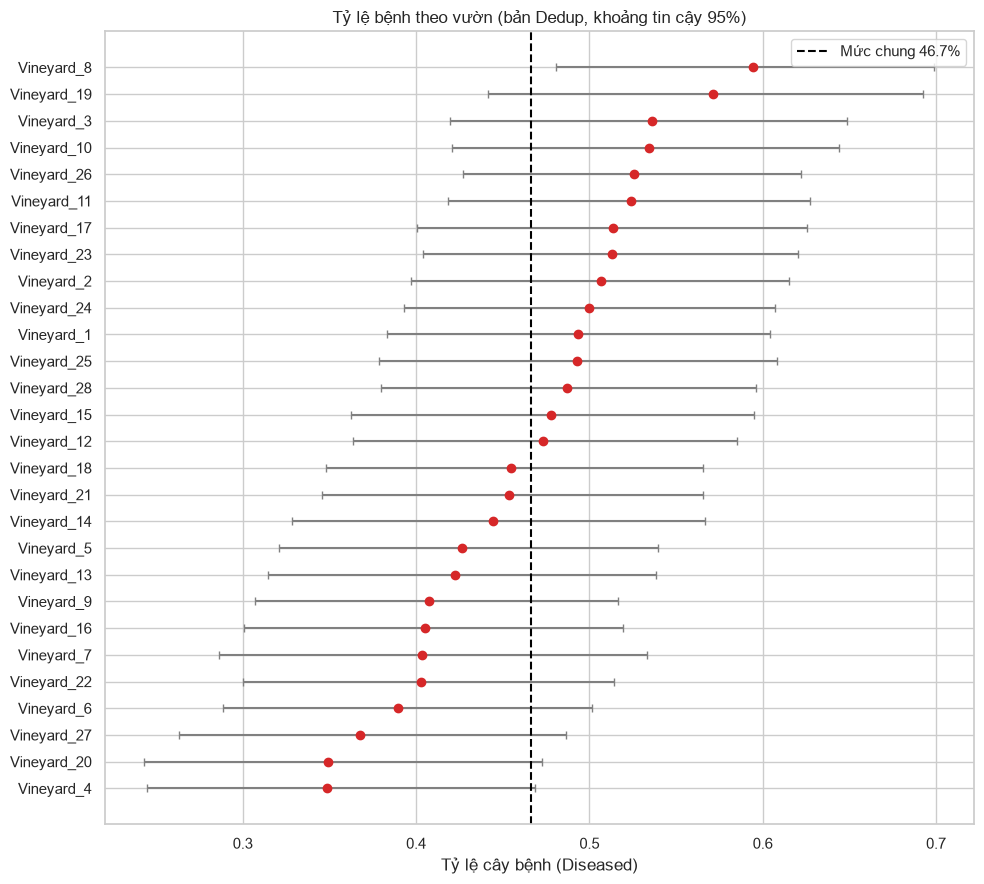

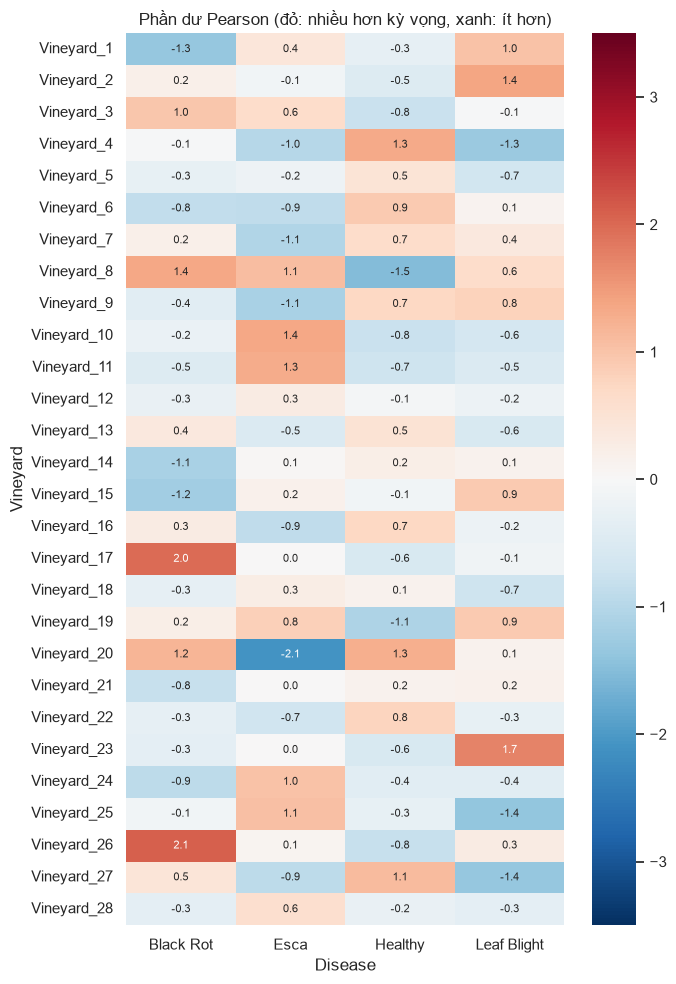

In [6]:
# Biểu đồ: tỷ lệ bệnh từng vườn kèm khoảng tin cậy 95%
order = vy.sort_values("Ty_le_benh").index
fig, ax = plt.subplots(figsize=(10, 9))
yy = np.arange(len(order))
ax.errorbar(vy.loc[order, "Ty_le_benh"], yy,
            xerr=[vy.loc[order, "Ty_le_benh"] - vy.loc[order, "CI_thap"],
                  vy.loc[order, "CI_cao"] - vy.loc[order, "Ty_le_benh"]],
            fmt="o", color="tab:red", ecolor="gray", capsize=3)
ax.axvline(overall_rate, color="black", ls="--", label=f"Mức chung {overall_rate:.1%}")
ax.set_yticks(yy); ax.set_yticklabels(order); ax.set_xlabel("Tỷ lệ cây bệnh (Diseased)")
ax.set_title("Tỷ lệ bệnh theo vườn (bản Dedup, khoảng tin cậy 95%)"); ax.legend()
plt.tight_layout(); savefig("bai2_ty_le_benh_theo_vuon"); plt.show()

# Phần dư Pearson: vườn nào có loại bệnh nhiều/ít hơn kỳ vọng
resid = pd.DataFrame((ct.values - expected) / np.sqrt(expected), index=ct.index, columns=ct.columns)
plt.figure(figsize=(7, 10))
sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3.5, vmax=3.5, annot_kws={"size": 8})
plt.title("Phần dư Pearson (đỏ: nhiều hơn kỳ vọng, xanh: ít hơn)")
plt.tight_layout(); savefig("bai2_phan_du_vuon_x_benh"); plt.show()

In [7]:
# Kiểm định từng ô (vườn × loại bệnh) so với tỷ lệ chung, hiệu chỉnh FDR
overall_prop = d["Disease"].value_counts(normalize=True)
cell_rows = []
for v in VINEYARDS:
    n = int(ct.loc[v].sum())
    for c in CLASSES:
        k = int(ct.loc[v, c])
        cell_rows.append(dict(Vineyard=v, Loai=c, k=k, n=n, Ty_le=k / n, Ty_le_chung=overall_prop[c],
                              p_value=stats.binomtest(k, n, overall_prop[c]).pvalue))
cells = pd.DataFrame(cell_rows)
cells["p_adj_FDR"] = bh_fdr(cells["p_value"].values)
sig = cells[cells["p_adj_FDR"] < ALPHA]
print(f"Số ô (vườn × loại) khác tỷ lệ chung có ý nghĩa sau FDR: {len(sig)}/{len(cells)}")
print("\n10 ô có p nhỏ nhất:")
display(cells.sort_values("p_value").head(10).round(4))

Số ô (vườn × loại) khác tỷ lệ chung có ý nghĩa sau FDR: 0/112

10 ô có p nhỏ nhất:


,Vineyard,Loai,k,n,Ty_le,Ty_le_chung,p_value,p_adj_FDR
77,Vineyard_20,Esca,12,63,0.1905,0.3454,0.0111,0.9665
30,Vineyard_8,Healthy,30,74,0.4054,0.5335,0.0353,0.9665
100,Vineyard_26,Black Rot,9,97,0.0928,0.0469,0.0481,0.9665
14,Vineyard_4,Healthy,43,66,0.6515,0.5335,0.0637,0.9665
78,Vineyard_20,Healthy,41,63,0.6508,0.5335,0.0764,0.9665
91,Vineyard_23,Leaf Blight,10,78,0.1282,0.0743,0.0804,0.9665
64,Vineyard_17,Black Rot,7,72,0.0972,0.0469,0.0833,0.9665
37,Vineyard_10,Esca,32,73,0.4384,0.3454,0.1091,0.9665
41,Vineyard_11,Esca,36,84,0.4286,0.3454,0.1097,0.9665
106,Vineyard_27,Healthy,43,68,0.6324,0.5335,0.1143,0.9665


**5.1 Chi-square vườn × bệnh trên các phiên bản dữ liệu**

Cột `p_hoan_vi_theo_nhom` là p-value bằng **hoán vị nhãn bệnh giữa các nhóm ảnh** (với Dedup mỗi ảnh là một nhóm; với Full các bản ghi cùng ảnh không độc lập nên cách này tính đến cấu trúc nhóm). Hoán vị không cần giả định số mong đợi ≥ 5 như chi-square chuẩn. Bản **All** có thêm các ca nhãn mơ hồ, dùng để xem kết luận có nhạy với việc loại chúng không.

In [8]:
attrs = {"Vineyard": "Vineyard", "Weather": "Weather", "Lighting": "Lighting", "Time": "Time"}

rows = []
for name, dd in VERSIONS.items():
    for a, col in attrs.items():
        tab = pd.crosstab(dd[col], dd["Disease"])
        chi2_, p_std, dof_, _ = stats.chi2_contingency(tab)
        row = dict(Phien_ban=f"{name} ({len(dd)})", Thuoc_tinh=a, Chi2=round(chi2_, 2), p_chuan=round(p_std, 4),
                   Cramers_V=round(cramers_v(chi2_, tab.values.sum(), tab.shape), 4), p_hoan_vi_theo_nhom=np.nan)
        # Dedup: mỗi ảnh một dòng nên hoán vị theo nhóm chính là hoán vị theo bản ghi.
        # All gồm cả ảnh mơ hồ nằm ở 2 lớp (không có nhãn nhóm nhất quán) nên không tính hoán vị.
        if name in ("Dedup", "Full"):
            _, p_perm = group_perm_chi2(dd, col)
            row["p_hoan_vi_theo_nhom"] = round(p_perm, 4)
        rows.append(row)
chi_versions = pd.DataFrame(rows)
display(chi_versions)
display(chi_versions.pivot(index="Thuoc_tinh", columns="Phien_ban", values="p_chuan"))

,Phien_ban,Thuoc_tinh,Chi2,p_chuan,Cramers_V,p_hoan_vi_theo_nhom
0,Dedup (2047),Vineyard,72.57,0.7369,0.1087,0.7263
1,Dedup (2047),Weather,11.38,0.0774,0.0527,0.0749
2,Dedup (2047),Lighting,8.13,0.2290,0.0446,0.2268
3,Dedup (2047),Time,3.79,0.7054,0.0304,0.7203
4,Full (2904),Vineyard,86.44,0.3192,0.0996,0.3317
5,Full (2904),Weather,11.82,0.0660,0.0451,0.0609
6,Full (2904),Lighting,5.29,0.5070,0.0302,0.4476
7,Full (2904),Time,4.56,0.6011,0.0280,0.5754
8,All (3476),Vineyard,95.98,0.1224,0.0959,NaN
9,All (3476),Weather,7.42,0.2841,0.0327,NaN


Phien_ban,All (3476),Dedup (2047),Full (2904)
Thuoc_tinh,,,
Lighting,0.4847,0.2290,0.5070
Time,0.4713,0.7054,0.6011
Vineyard,0.1224,0.7369,0.3192
Weather,0.2841,0.0774,0.0660


**5.2 Xếp hạng vườn có ổn định không?**

Nếu vườn thật sự khác nhau về tỷ lệ bệnh thì xếp hạng phải giống nhau giữa các phiên bản và giữa hai nửa ngẫu nhiên của dữ liệu. Hai cách kiểm tra:
1. Tương quan Spearman của tỷ lệ bệnh từng vườn giữa các phiên bản dữ liệu.
2. **Chia đôi ngẫu nhiên** các mẫu trong từng vườn (bản Dedup), tính tương quan giữa tỷ lệ bệnh của hai nửa, lặp nhiều lần. Tương quan gần 0 nghĩa là chênh lệch giữa các vườn chủ yếu là nhiễu lấy mẫu.

Tương quan Spearman của tỷ lệ bệnh theo vườn giữa các phiên bản:


,Dedup,Full,All
Dedup,1.000,0.867,0.784
Full,0.867,1.000,0.923
All,0.784,0.923,1.000


Số vườn trùng nhau trong top 5 vườn có tỷ lệ bệnh cao nhất:


,Dedup,Full,All
Dedup,5,4,4
Full,4,5,5
All,4,5,5



Tương quan giữa hai nửa ngẫu nhiên (bản Dedup): trung bình = 0.163, khoảng 95% = [-0.118, 0.453]
Gần 0 nghĩa là xếp hạng tỷ lệ bệnh giữa các vườn không ổn định, chủ yếu do nhiễu lấy mẫu.


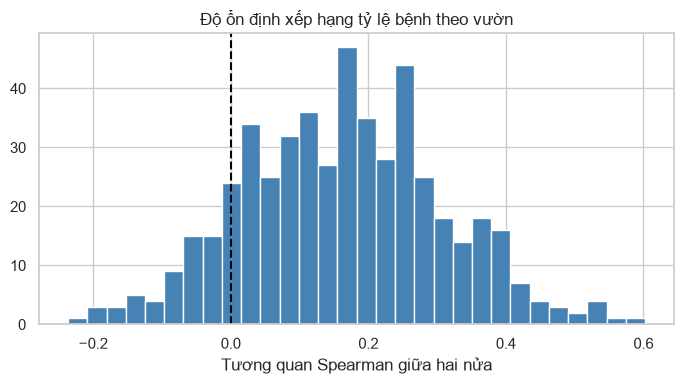

In [9]:
rate_by_version = pd.DataFrame({
    name: dd.groupby("Vineyard")["is_diseased"].mean().loc[VINEYARDS] for name, dd in VERSIONS.items()
})
print("Tương quan Spearman của tỷ lệ bệnh theo vườn giữa các phiên bản:")
display(rate_by_version.corr(method="spearman").round(3))

top5 = {name: set(rate_by_version[name].nlargest(5).index) for name in rate_by_version}
print("Số vườn trùng nhau trong top 5 vườn có tỷ lệ bệnh cao nhất:")
display(pd.DataFrame({a: {b: len(top5[a] & top5[b]) for b in top5} for a in top5}))

# Chia đôi ngẫu nhiên trong từng vườn (bản Dedup)
rng = np.random.default_rng(SEED)
vc = pd.Categorical(df_dedup["Vineyard"], categories=VINEYARDS).codes
y_bin = df_dedup["is_diseased"].values
corrs = []
for _ in range(N_SPLIT_HALF):
    half = rng.random(len(df_dedup)) < 0.5
    r1 = np.array([y_bin[(vc == i) & half].mean() for i in range(len(VINEYARDS))])
    r2 = np.array([y_bin[(vc == i) & ~half].mean() for i in range(len(VINEYARDS))])
    corrs.append(stats.spearmanr(r1, r2).statistic)
corrs = np.array(corrs)
print(f"\nTương quan giữa hai nửa ngẫu nhiên (bản Dedup): trung bình = {corrs.mean():.3f}, "
      f"khoảng 95% = [{np.quantile(corrs, 0.025):.3f}, {np.quantile(corrs, 0.975):.3f}]")
print("Gần 0 nghĩa là xếp hạng tỷ lệ bệnh giữa các vườn không ổn định, chủ yếu do nhiễu lấy mẫu.")

plt.figure(figsize=(7, 4))
plt.hist(corrs, bins=30, color="steelblue", edgecolor="white")
plt.axvline(0, color="black", ls="--")
plt.xlabel("Tương quan Spearman giữa hai nửa"); plt.title("Độ ổn định xếp hạng tỷ lệ bệnh theo vườn")
plt.tight_layout(); savefig("bai2_do_on_dinh_xep_hang"); plt.show()

In [10]:
# Bảng vườn cần ưu tiên khảo sát (xếp theo cận dưới khoảng tin cậy để tránh vườn ít mẫu)
priority = vy.assign(Hang_theo_ty_le=vy["Ty_le_benh"].rank(ascending=False).astype(int)) \
             .sort_values("CI_thap", ascending=False)[
    ["So_mau", "Ty_le_benh", "CI_thap", "CI_cao", "Benh_chu_dao", "p_adj_FDR", "Khac_muc_chung", "Hang_theo_ty_le"]]
print("Xếp hạng vườn theo cận dưới của khoảng tin cậy (cao -> thấp):")
display(priority.head(10).round(4))
if not priority["Khac_muc_chung"].any():
    print("⚠️ Không vườn nào có tỷ lệ bệnh khác mức chung một cách có ý nghĩa thống kê. "
          "Bảng trên chỉ mang tính tham khảo, không nên coi là danh sách ưu tiên khảo sát.")

Xếp hạng vườn theo cận dưới của khoảng tin cậy (cao -> thấp):


,So_mau,Ty_le_benh,CI_thap,CI_cao,Benh_chu_dao,p_adj_FDR,Khac_muc_chung,Hang_theo_ty_le
Vineyard,,,,,,,,
Vineyard_8,74,0.5946,0.4808,0.6991,Esca,0.7008,False,1
Vineyard_19,56,0.5714,0.4414,0.6923,Esca,0.7008,False,2
Vineyard_26,97,0.5258,0.4273,0.6223,Esca,0.7008,False,5
Vineyard_10,73,0.5342,0.4210,0.6441,Esca,0.7008,False,4
Vineyard_3,69,0.5362,0.4198,0.6489,Esca,0.7008,False,3
Vineyard_11,84,0.5238,0.4183,0.6272,Esca,0.7008,False,6
Vineyard_23,78,0.5128,0.4039,0.6205,Esca,0.7702,False,8
Vineyard_17,72,0.5139,0.4007,0.6257,Esca,0.7702,False,7
Vineyard_2,77,0.5065,0.3972,0.6152,Esca,0.7702,False,9


⚠️ Không vườn nào có tỷ lệ bệnh khác mức chung một cách có ý nghĩa thống kê. Bảng trên chỉ mang tính tham khảo, không nên coi là danh sách ưu tiên khảo sát.


**6. GOM NHÓM CÁC VƯỜN CÓ ĐẶC ĐIỂM BỆNH TƯƠNG ĐỒNG**

Mỗi vườn được biểu diễn bằng vector tỷ lệ 4 lớp bệnh. Gom nhóm bằng K-Means (chọn k theo silhouette) và phân cấp Ward. Để biết cụm có **thật** hay chỉ do ngẫu nhiên, so silhouette quan sát với phân phối khi **hoán vị nhãn bệnh**: giữa các bản ghi với bản Dedup, giữa các **nhóm ảnh** với bản Full. Mantel test kiểm tra các vườn gần nhau về địa lý có giống nhau về hồ sơ bệnh không.

[Dedup] k tốt nhất = 2, silhouette = 0.496 | khi nhãn ngẫu nhiên: TB 0.412, phân vị 95% 0.506 | p hoán vị = 0.0697
[Full] k tốt nhất = 2, silhouette = 0.343 | khi nhãn ngẫu nhiên: TB 0.406, phân vị 95% 0.485 | p hoán vị = 0.9254

ARI giữa cụm của Dedup và Full (cùng k = 2): 0.492


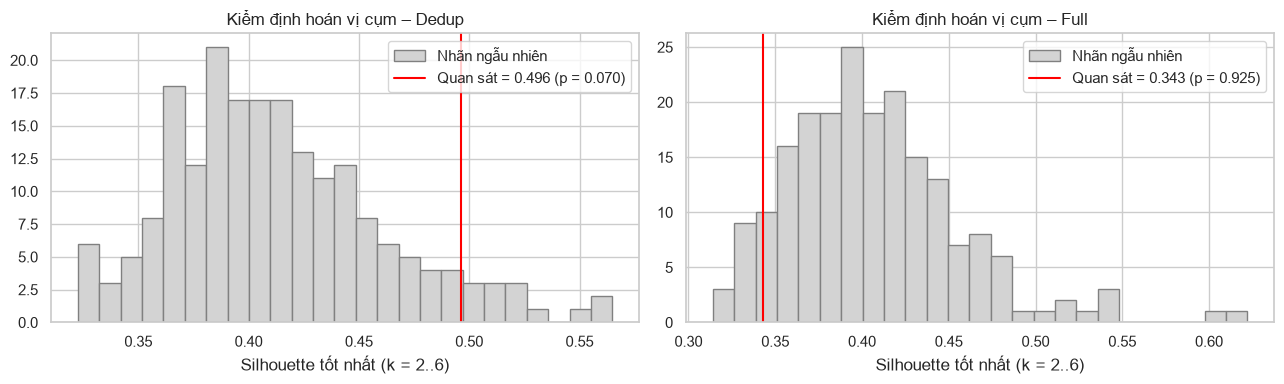

In [11]:
def profile(d):
    ct_ = pd.crosstab(d["Vineyard"], d["Disease"]).reindex(index=VINEYARDS, columns=CLASSES, fill_value=0)
    return ct_.div(ct_.sum(1), axis=0)

def best_kmeans(M, ks=range(2, 7), n_init=5, seed=SEED):
    best = (-1.0, None, None)
    for k in ks:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(M)
        s = silhouette_score(M, km.labels_)
        if s > best[0]:
            best = (s, k, km.labels_)
    return best

def prop_matrix(vcode, ycode):
    cnt = np.bincount(vcode * K + ycode, minlength=len(VINEYARDS) * K).reshape(len(VINEYARDS), K)
    return cnt / np.maximum(cnt.sum(1, keepdims=True), 1)

coords = df_dedup.groupby("Vineyard")[["Lat", "Lon"]].mean().loc[VINEYARDS]

cluster_res = {}
for name in ["Dedup", "Full"]:
    dd = VERSIONS[name]
    P_ = profile(dd)
    obs_sil, k_best, labels_ = best_kmeans(P_.values)
    vcode = pd.Categorical(dd["Vineyard"], categories=VINEYARDS).codes
    rng = np.random.default_rng(SEED)
    if name == "Dedup":
        ycode = pd.Categorical(dd["Disease"], categories=CLASSES).codes
        null = [best_kmeans(prop_matrix(vcode, rng.permutation(ycode)))[0] for _ in range(N_PERM_CLUSTER)]
    else:
        g_codes, y_group, cls_names = group_structure(dd)
        cls_map = np.array([CLASSES.index(c) for c in cls_names])      # đưa về cùng thứ tự lớp
        null = [best_kmeans(prop_matrix(vcode, cls_map[rng.permutation(y_group)][g_codes]))[0]
                for _ in range(N_PERM_CLUSTER)]
    null = np.array(null)
    p_cl = (1 + (null >= obs_sil).sum()) / (1 + len(null))
    cluster_res[name] = dict(P=P_, sil=obs_sil, k=k_best, labels=labels_, null=null, p=p_cl)
    print(f"[{name}] k tốt nhất = {k_best}, silhouette = {obs_sil:.3f} | "
          f"khi nhãn ngẫu nhiên: TB {null.mean():.3f}, phân vị 95% {np.quantile(null, 0.95):.3f} | p hoán vị = {p_cl:.4f}")

# Hai cách gom nhóm có cho cùng kết quả không? (ARI = 1: giống hệt, ~0: như ngẫu nhiên)
k_ref = cluster_res["Dedup"]["k"]
lab_full_same_k = KMeans(n_clusters=k_ref, n_init=5, random_state=SEED).fit(cluster_res["Full"]["P"].values).labels_
print(f"\nARI giữa cụm của Dedup và Full (cùng k = {k_ref}): {adjusted_rand_score(cluster_res['Dedup']['labels'], lab_full_same_k):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, name in zip(ax, ["Dedup", "Full"]):
    r = cluster_res[name]
    a.hist(r["null"], bins=25, color="lightgray", edgecolor="gray", label="Nhãn ngẫu nhiên")
    a.axvline(r["sil"], color="red", label=f"Quan sát = {r['sil']:.3f} (p = {r['p']:.3f})")
    a.set_title(f"Kiểm định hoán vị cụm – {name}"); a.set_xlabel("Silhouette tốt nhất (k = 2..6)"); a.legend()
plt.tight_layout(); savefig("bai2_kiem_dinh_hoan_vi_cum"); plt.show()

Hồ sơ trung bình của từng cụm (tỷ lệ các lớp):


Disease,Black Rot,Esca,Healthy,Leaf Blight,So_vuon,Ty_le_benh
Cum,,,,,,
0,0.046,0.380,0.495,0.080,18,0.505
1,0.049,0.279,0.608,0.065,10,0.392


Cụm 0: V1, V2, V3, V8, V10, V11, V12, V14, V15, V17, V18, V19, V21, V23, V24, V25, V26, V28
Cụm 1: V4, V5, V6, V7, V9, V13, V16, V20, V22, V27


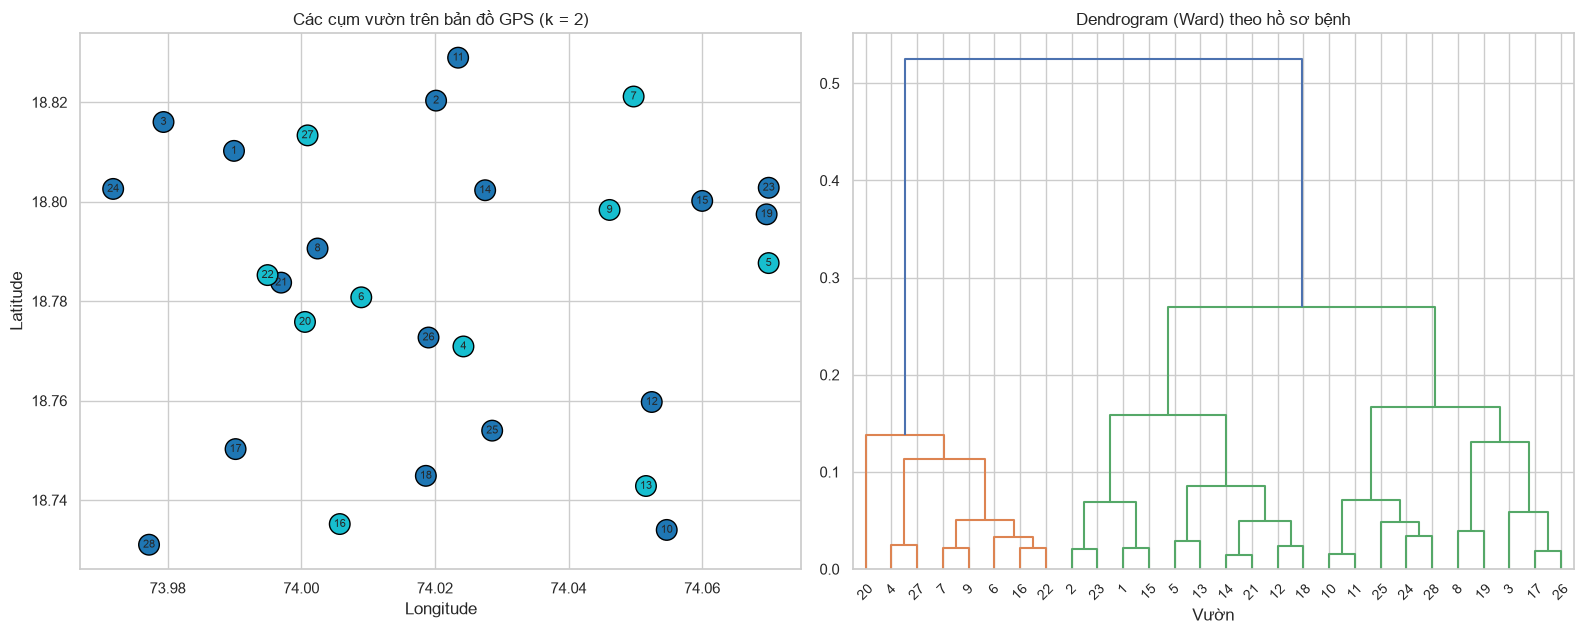

In [12]:
# Mô tả cụm (bản Dedup), bản đồ GPS và dendrogram
r = cluster_res["Dedup"]; P = r["P"]; labels = r["labels"]; best_k = r["k"]
vy_cluster = pd.Series(labels, index=VINEYARDS, name="Cum")
profile_tab = P.groupby(vy_cluster).mean().round(3)
profile_tab["So_vuon"] = vy_cluster.value_counts().sort_index()
profile_tab["Ty_le_benh"] = (1 - profile_tab["Healthy"]).round(3)
print("Hồ sơ trung bình của từng cụm (tỷ lệ các lớp):")
display(profile_tab)
for c in sorted(vy_cluster.unique()):
    print(f"Cụm {c}:", ", ".join(v.replace("Vineyard_", "V") for v in vy_cluster[vy_cluster == c].index))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
ax[0].scatter(coords["Lon"], coords["Lat"], c=labels, cmap="tab10", s=220, edgecolor="black")
for v, (la, lo) in coords.iterrows():
    ax[0].annotate(v.split("_")[-1], (lo, la), ha="center", va="center", fontsize=8)
ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].set_title(f"Các cụm vườn trên bản đồ GPS (k = {best_k})")
Z = linkage(P.values, method="ward")
dendrogram(Z, labels=[v.split("_")[-1] for v in VINEYARDS], ax=ax[1], color_threshold=0.7 * Z[-1, 2])
ax[1].set_title("Dendrogram (Ward) theo hồ sơ bệnh"); ax[1].set_xlabel("Vườn")
plt.tight_layout(); savefig("bai2_cum_vuon_ban_do_dendrogram"); plt.show()

[Dedup] Mantel: Spearman giữa khoảng cách địa lý và khác biệt hồ sơ bệnh = -0.112, p = 0.0779
[Full] Mantel: Spearman giữa khoảng cách địa lý và khác biệt hồ sơ bệnh = -0.060, p = 0.4386


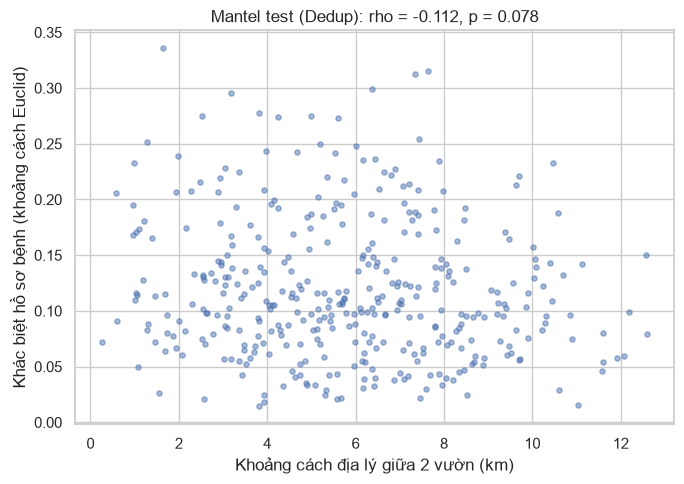

In [13]:
# Mantel test: vườn gần nhau có hồ sơ bệnh giống nhau hơn không?
lat0 = coords["Lat"].mean()
xy = np.c_[coords["Lat"] * 111.0, coords["Lon"] * 111.0 * np.cos(np.radians(lat0))]   # ~km
d_geo = pdist(xy)
mantel = {}
for name in ["Dedup", "Full"]:
    Pm = cluster_res[name]["P"].values
    d_dis = pdist(Pm)
    obs_rho = stats.spearmanr(d_geo, d_dis).statistic
    rng = np.random.default_rng(SEED)
    perm = np.array([stats.spearmanr(d_geo, pdist(Pm[rng.permutation(len(Pm))])).statistic for _ in range(N_PERMUTATIONS)])
    p_m = (1 + (np.abs(perm) >= abs(obs_rho)).sum()) / (1 + N_PERMUTATIONS)
    mantel[name] = (obs_rho, p_m)
    print(f"[{name}] Mantel: Spearman giữa khoảng cách địa lý và khác biệt hồ sơ bệnh = {obs_rho:.3f}, p = {p_m:.4f}")

Pm = cluster_res["Dedup"]["P"].values
plt.figure(figsize=(7, 5))
plt.scatter(d_geo, pdist(Pm), s=14, alpha=0.5)
plt.xlabel("Khoảng cách địa lý giữa 2 vườn (km)"); plt.ylabel("Khác biệt hồ sơ bệnh (khoảng cách Euclid)")
plt.title(f"Mantel test (Dedup): rho = {mantel['Dedup'][0]:.3f}, p = {mantel['Dedup'][1]:.3f}")
plt.tight_layout(); savefig("bai2_mantel_gps"); plt.show()

**7. LUẬT KẾT HỢP: MÔI TRƯỜNG / VỊ TRÍ ⇒ TÌNH TRẠNG BỆNH**

Mỗi luật có dạng `{điều kiện môi trường / vườn} ⇒ {loại bệnh}`: **support** (tỷ lệ mẫu thỏa cả hai vế), **confidence** (xác suất có bệnh khi thỏa điều kiện), **lift** (confidence so với tỷ lệ bệnh chung; ≈ 1 là không có liên hệ). Luật được khai thác trên bản **Dedup** (các bản ghi độc lập nên kiểm định Fisher hợp lệ), mỗi luật có p-value hiệu chỉnh FDR. Lift cũng được tính trên bản Full để xem có ổn định không.

[Dedup] Số luật được xét: 1415 | có ý nghĩa sau FDR (< 0.05): 0
[Dedup] Lift nhỏ nhất / lớn nhất: 0.00 / 3.88

Top 15 luật theo lift (Consequent là loại bệnh cụ thể):


,Antecedent,Consequent,n_antecedent,n_both,Support,Confidence,Lift,p_value,p_adj_FDR
670,Vineyard=Vineyard_26 & Weather=Clear,Disease=Black Rot,33,6,0.0029,0.1818,3.8769,0.0036,1.0
890,Vineyard=Vineyard_17 & Lighting=Overcast,Disease=Black Rot,29,5,0.0024,0.1724,3.6764,0.0099,1.0
550,Vineyard=Vineyard_17 & Weather=Clear,Disease=Black Rot,30,5,0.0024,0.1667,3.5538,0.0114,1.0
1240,Vineyard=Vineyard_20 & Time=Evening,Disease=Black Rot,24,4,0.0020,0.1667,3.5538,0.0234,1.0
1360,Vineyard=Vineyard_3 & Time=Morning,Disease=Black Rot,29,4,0.0020,0.1379,2.9411,0.0438,1.0
1005,Vineyard=Vineyard_26 & Lighting=Overcast,Disease=Black Rot,37,5,0.0024,0.1351,2.8815,0.0270,1.0
1195,Vineyard=Vineyard_17 & Time=Afternoon,Disease=Black Rot,23,3,0.0015,0.1304,2.7812,0.0898,1.0
918,Vineyard=Vineyard_19 & Lighting=Overcast,Disease=Leaf Blight,25,5,0.0024,0.2000,2.6934,0.0334,1.0
920,Vineyard=Vineyard_2 & Lighting=Natural sunlight,Disease=Black Rot,33,4,0.0020,0.1212,2.5846,0.0656,1.0
1320,Vineyard=Vineyard_26 & Time=Evening,Disease=Black Rot,34,4,0.0020,0.1176,2.5086,0.0718,1.0



Top 10 luật dẫn tới Health=Diseased:


,Antecedent,Consequent,n_antecedent,n_both,Support,Confidence,Lift,p_value,p_adj_FDR
1404,Vineyard=Vineyard_8 & Time=Morning,Health=Diseased,23,17,0.0083,0.7391,1.5843,0.0106,1.0
599,Vineyard=Vineyard_2 & Weather=Windy,Health=Diseased,24,17,0.0083,0.7083,1.5183,0.0222,1.0
639,Vineyard=Vineyard_23 & Weather=Clear,Health=Diseased,27,19,0.0093,0.7037,1.5084,0.0182,1.0
1294,Vineyard=Vineyard_24 & Time=Afternoon,Health=Diseased,25,17,0.0083,0.6800,1.4575,0.0421,1.0
724,Vineyard=Vineyard_3 & Weather=Humid,Health=Diseased,21,14,0.0068,0.6667,1.4290,0.0788,1.0
784,Vineyard=Vineyard_8 & Weather=Windy,Health=Diseased,30,20,0.0098,0.6667,1.4290,0.0408,1.0
894,Vineyard=Vineyard_17 & Lighting=Overcast,Health=Diseased,29,19,0.0093,0.6552,1.4043,0.0590,1.0
1134,Vineyard=Vineyard_11 & Time=Afternoon,Health=Diseased,29,19,0.0093,0.6552,1.4043,0.0590,1.0
1094,Vineyard=Vineyard_8 & Lighting=Partly cloudy,Health=Diseased,23,15,0.0073,0.6522,1.3979,0.0921,1.0
1109,Vineyard=Vineyard_1 & Time=Evening,Health=Diseased,28,18,0.0088,0.6429,1.3779,0.0844,1.0



Tương quan Spearman của lift giữa Dedup và Full trên 1350 luật chung: 0.645


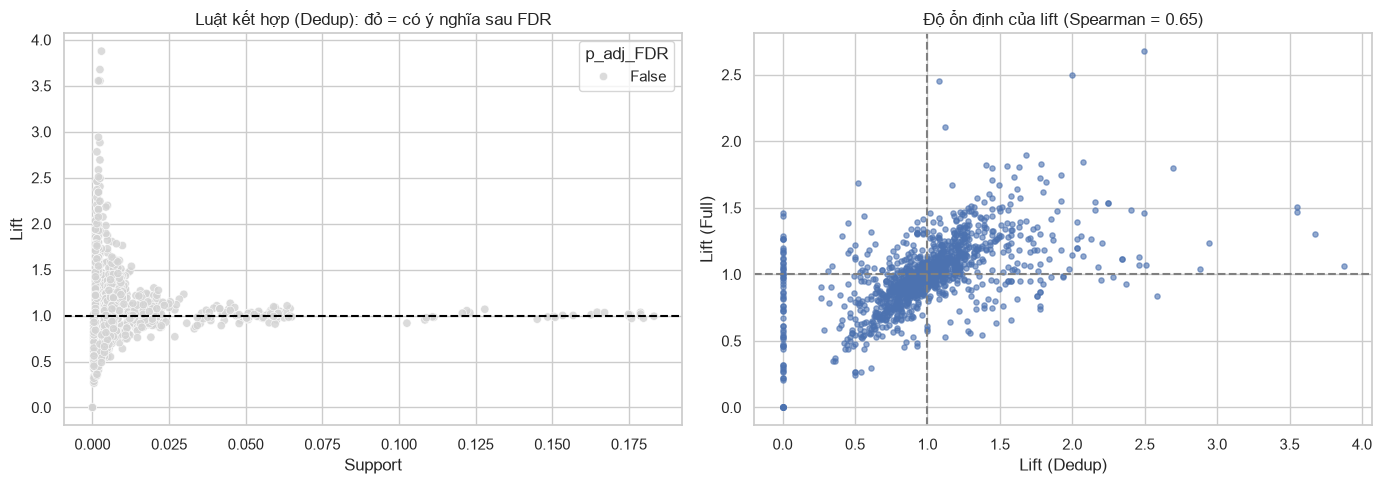

In [14]:
def mine_rules(data, env_attrs=("Weather", "Lighting", "Time"), min_support=MIN_SUPPORT):
    N = len(data)
    combos = [c for r in (1, 2, 3) for c in itertools.combinations(env_attrs, r)]
    combos += [("Vineyard",)] + [("Vineyard", a) for a in env_attrs]
    targets = [("Disease", c) for c in CLASSES] + [("Health", "Diseased")]
    tot = {t: int((data[t[0]] == t[1]).sum()) for t in targets}
    rows = []
    for cols in combos:
        for key, g in data.groupby(list(cols)):
            key = key if isinstance(key, tuple) else (key,)
            n_a = len(g)
            if n_a / N < min_support:
                continue
            ant = " & ".join(f"{c}={v}" for c, v in zip(cols, key))
            for t in targets:
                k, n_c = int((g[t[0]] == t[1]).sum()), tot[t]
                conf, lift = k / n_a, (k / n_a) / (n_c / N)
                p = stats.fisher_exact([[k, n_a - k], [n_c - k, N - n_a - n_c + k]])[1]
                rows.append(dict(Antecedent=ant, Consequent=f"{t[0]}={t[1]}", n_antecedent=n_a, n_both=k,
                                 Support=k / N, Confidence=conf, Lift=lift, p_value=p))
    out = pd.DataFrame(rows)
    out["p_adj_FDR"] = bh_fdr(out["p_value"].values)
    return out

rules = mine_rules(df_dedup)
rules_full = mine_rules(df_full)
print(f"[Dedup] Số luật được xét: {len(rules)} | có ý nghĩa sau FDR (< {ALPHA}): {int((rules['p_adj_FDR'] < ALPHA).sum())}")
print(f"[Dedup] Lift nhỏ nhất / lớn nhất: {rules['Lift'].min():.2f} / {rules['Lift'].max():.2f}")

print("\nTop 15 luật theo lift (Consequent là loại bệnh cụ thể):")
display(rules[rules["Consequent"].str.startswith("Disease")].sort_values("Lift", ascending=False).head(15).round(4))
print("\nTop 10 luật dẫn tới Health=Diseased:")
display(rules[rules["Consequent"] == "Health=Diseased"].sort_values("Lift", ascending=False).head(10).round(4))

# Lift có ổn định giữa Dedup và Full?
m = rules.merge(rules_full[["Antecedent", "Consequent", "Lift"]], on=["Antecedent", "Consequent"], suffixes=("_dedup", "_full"))
rho_lift = stats.spearmanr(m["Lift_dedup"], m["Lift_full"]).statistic
print(f"\nTương quan Spearman của lift giữa Dedup và Full trên {len(m)} luật chung: {rho_lift:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=rules, x="Support", y="Lift", hue=rules["p_adj_FDR"] < ALPHA,
                palette={False: "lightgray", True: "red"}, alpha=0.8, ax=ax[0])
ax[0].axhline(1, color="black", ls="--"); ax[0].set_title("Luật kết hợp (Dedup): đỏ = có ý nghĩa sau FDR")
ax[1].scatter(m["Lift_dedup"], m["Lift_full"], s=14, alpha=0.6)
ax[1].axhline(1, color="gray", ls="--"); ax[1].axvline(1, color="gray", ls="--")
ax[1].set_xlabel("Lift (Dedup)"); ax[1].set_ylabel("Lift (Full)"); ax[1].set_title(f"Độ ổn định của lift (Spearman = {rho_lift:.2f})")
plt.tight_layout(); savefig("bai2_luat_ket_hop"); plt.show()

**8. METADATA CÓ DỰ ĐOÁN ĐƯỢC LOẠI BỆNH KHÔNG?**

Dự đoán `Disease` từ vườn, thời tiết, ánh sáng, thời điểm chụp bằng cross-validation 5 fold. Bản Dedup dùng `StratifiedKFold`; bản Full dùng `StratifiedGroupKFold` theo nhóm ảnh để các bản sao của cùng một ảnh không nằm ở cả train và test. So với mô hình đoán lớp phổ biến nhất và kiểm định hoán vị.

In [15]:
feat_cols = ["Vineyard", "Weather", "Lighting", "Time"]
scoring = ["accuracy", "balanced_accuracy", "f1_macro"]

def make_models():
    return {
        "Dummy (lớp phổ biến nhất)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    }

rows = []
for name in ["Dedup", "Full"]:
    dd = VERSIONS[name]
    X = pd.get_dummies(dd[feat_cols]).astype(int)
    yv = pd.Categorical(dd["Disease"], categories=CLASSES).codes
    if name == "Dedup":
        cv, groups = StratifiedKFold(5, shuffle=True, random_state=SEED), None
    else:
        cv, groups = StratifiedGroupKFold(5, shuffle=True, random_state=SEED), dd["MD5"].values
    for mname, mdl in make_models().items():
        res = cross_validate(mdl, X, yv, cv=cv, groups=groups, scoring=scoring)
        rows.append(dict(Phien_ban=name, Model=mname,
                         Accuracy=res["test_accuracy"].mean(), Balanced_Acc=res["test_balanced_accuracy"].mean(),
                         Macro_F1=res["test_f1_macro"].mean(), Macro_F1_std=res["test_f1_macro"].std()))
meta_cv = pd.DataFrame(rows)
display(meta_cv.round(4))

# Kiểm định hoán vị cho Random Forest (bản Dedup)
X = pd.get_dummies(df_dedup[feat_cols]).astype(int)
yv = pd.Categorical(df_dedup["Disease"], categories=CLASSES).codes
rf_perm = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
score, perm_scores, p_perm = permutation_test_score(
    rf_perm, X, yv, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="balanced_accuracy",
    n_permutations=N_PERM_MODEL, random_state=SEED, n_jobs=1)
print(f"Random Forest (Dedup): balanced accuracy = {score:.3f} | khi nhãn ngẫu nhiên = {perm_scores.mean():.3f} ± {perm_scores.std():.3f} | p = {p_perm:.4f}")
print(f"Tỷ lệ lớp phổ biến nhất (accuracy của mô hình đoán bừa): {pd.Series(yv).value_counts(normalize=True).max():.3f} | balanced accuracy đoán bừa = {1 / K:.3f}")

,Phien_ban,Model,Accuracy,Balanced_Acc,Macro_F1,Macro_F1_std
0,Dedup,Dummy (lớp phổ biến nhất),0.5335,0.2500,0.1739,0.0004
1,Dedup,Logistic Regression,0.5149,0.2468,0.1942,0.0070
2,Dedup,Decision Tree (depth=4),0.5291,0.2504,0.1853,0.0049
3,Dedup,Random Forest,0.5100,0.2459,0.1983,0.0061
4,Full,Dummy (lớp phổ biến nhất),0.3816,0.2500,0.1381,0.0006
5,Full,Logistic Regression,0.3578,0.2481,0.1911,0.0094
6,Full,Decision Tree (depth=4),0.3750,0.2502,0.1609,0.0116
7,Full,Random Forest,0.3530,0.2513,0.2097,0.0139


Random Forest (Dedup): balanced accuracy = 0.246 | khi nhãn ngẫu nhiên = 0.250 ± 0.005 | p = 0.8387
Tỷ lệ lớp phổ biến nhất (accuracy của mô hình đoán bừa): 0.533 | balanced accuracy đoán bừa = 0.250


**9. TỔNG HỢP KẾT QUẢ**

In [16]:
rf_dedup = meta_cv[(meta_cv["Phien_ban"] == "Dedup") & (meta_cv["Model"] == "Random Forest")].iloc[0]
print("=" * 72)
print("BÀI 2 – PHÂN BỐ BỆNH VÀ MỐI LIÊN HỆ MÔI TRƯỜNG: TỔNG HỢP")
print("=" * 72)
print(f"- Dữ liệu: Dedup {len(df_dedup)} ảnh duy nhất (chính), Full {len(df_full)} bản ghi (đối chứng), 28 vườn.")
print(f"- Tỷ lệ cây bệnh chung (Dedup): {overall_rate:.2%}; vườn thấp nhất {vy['Ty_le_benh'].min():.1%} – cao nhất {vy['Ty_le_benh'].max():.1%}")
_pv = chi_versions[chi_versions["Thuoc_tinh"] == "Vineyard"].set_index(chi_versions[chi_versions["Thuoc_tinh"] == "Vineyard"]["Phien_ban"].str.split(" ").str[0])
print(f"- Chi-square vườn × bệnh: Dedup p chuẩn = {p_chi_dedup:.4f}, p hoán vị = {_pv.loc['Dedup', 'p_hoan_vi_theo_nhom']}; "
      f"Full p hoán vị theo nhóm = {_pv.loc['Full', 'p_hoan_vi_theo_nhom']}")
print(f"- Số vườn khác mức chung có ý nghĩa (FDR): {int(vy['Khac_muc_chung'].sum())}/{len(vy)}; số ô vườn × loại có ý nghĩa: {len(sig)}/{len(cells)}")
print(f"- Độ ổn định xếp hạng vườn (tương quan hai nửa ngẫu nhiên): {corrs.mean():.3f}")
print(f"- Gom nhóm: Dedup k = {cluster_res['Dedup']['k']}, silhouette = {cluster_res['Dedup']['sil']:.3f}, p hoán vị = {cluster_res['Dedup']['p']:.4f}; "
      f"Full p = {cluster_res['Full']['p']:.4f}")
print(f"- Mantel (GPS vs hồ sơ bệnh): Dedup rho = {mantel['Dedup'][0]:.3f}, p = {mantel['Dedup'][1]:.4f}; Full rho = {mantel['Full'][0]:.3f}, p = {mantel['Full'][1]:.4f}")
print(f"- Luật kết hợp (Dedup): {int((rules['p_adj_FDR'] < ALPHA).sum())}/{len(rules)} có ý nghĩa sau FDR; lift {rules['Lift'].min():.2f}–{rules['Lift'].max():.2f}; ổn định Dedup–Full (Spearman) = {rho_lift:.3f}")
print(f"- Dự đoán bệnh từ metadata (Dedup, RF): balanced accuracy = {score:.3f} so với {perm_scores.mean():.3f} khi nhãn ngẫu nhiên (p = {p_perm:.4f}); mô hình đoán bừa = {1 / K:.3f}")
print("\nHình đã lưu trong:", OUTPUT_DIR.resolve())

BÀI 2 – PHÂN BỐ BỆNH VÀ MỐI LIÊN HỆ MÔI TRƯỜNG: TỔNG HỢP
- Dữ liệu: Dedup 2047 ảnh duy nhất (chính), Full 2904 bản ghi (đối chứng), 28 vườn.
- Tỷ lệ cây bệnh chung (Dedup): 46.65%; vườn thấp nhất 34.8% – cao nhất 59.5%
- Chi-square vườn × bệnh: Dedup p chuẩn = 0.7369, p hoán vị = 0.7263; Full p hoán vị theo nhóm = 0.3317
- Số vườn khác mức chung có ý nghĩa (FDR): 0/28; số ô vườn × loại có ý nghĩa: 0/112
- Độ ổn định xếp hạng vườn (tương quan hai nửa ngẫu nhiên): 0.163
- Gom nhóm: Dedup k = 2, silhouette = 0.496, p hoán vị = 0.0697; Full p = 0.9254
- Mantel (GPS vs hồ sơ bệnh): Dedup rho = -0.112, p = 0.0779; Full rho = -0.060, p = 0.4386
- Luật kết hợp (Dedup): 0/1415 có ý nghĩa sau FDR; lift 0.00–3.88; ổn định Dedup–Full (Spearman) = 0.645
- Dự đoán bệnh từ metadata (Dedup, RF): balanced accuracy = 0.246 so với 0.250 khi nhãn ngẫu nhiên (p = 0.8387); mô hình đoán bừa = 0.250

Hình đã lưu trong: D:\DataMining26\Smart-Vineyard\outputs\bai2


### Kết luận (điền sau khi chạy xong)

- **Vườn cần ưu tiên khảo sát:** ... (có vườn nào khác mức chung có ý nghĩa sau FDR không? xếp hạng có ổn định giữa hai nửa dữ liệu và giữa Dedup/Full không?)
- **Các cụm vườn:** ... (cụm có tốt hơn ngẫu nhiên không, theo p hoán vị ở cả Dedup và Full; hai cách gom nhóm có cho cùng kết quả không, theo ARI)
- **Vị trí GPS và hồ sơ bệnh (Mantel):** ...
- **Môi trường và bệnh (chi-square, luật kết hợp):** ... (lift có gần 1 không? có luật nào có ý nghĩa sau FDR không? lift có ổn định giữa Dedup và Full không?)
- **Metadata có dự đoán được bệnh không:** ... (so với mô hình đoán bừa)
- **Hạn chế:** metadata có dấu hiệu không gắn chặt với ảnh (cùng một ảnh gắn với nhiều vườn), mỗi vườn chỉ có khoảng 56–97 ảnh duy nhất, và đây chỉ là mối liên hệ trong dữ liệu, không phải quan hệ nhân quả.